# Screw / Bolt Counting — AI Approach (SAM — Segment Anything Model)

**Author:** Nikhil BT  
**Task:** Count items in images & overlay masks — accuracy > 95%  
**Method:** Meta's Segment Anything Model (SAM) — zero-shot automatic mask generation

## Strategy
SAM (ViT-B) is used in **automatic mask generation** mode — it generates candidate masks for all objects in the image using a dense grid of point prompts. We then:
1. Filter masks by area and aspect ratio (screw-sized objects only)
2. Remove overlapping duplicate masks (NMS-style IoU deduplication)
3. Overlay coloured masks and count

## Why SAM (Zero-Shot)?
No annotated training data is provided in the challenge. SAM was pre-trained on 1 billion masks and generalises to industrial objects (screws, bolts) without domain-specific fine-tuning.

## Training Method
- **SAM ViT-B**: Pre-trained by Meta AI on SA-1B dataset (11M images, 1B masks)
- No additional training performed — zero-shot inference only
- If annotated data were available: fine-tune SAM's mask decoder with domain-specific prompts

In [55]:
!pip install segment-anything opencv-python-headless numpy matplotlib torch torchvision -q

import os
if not os.path.exists('sam_vit_b_01ec64.pth'):
    !wget -q https://dl.fbaipublicfiles.com/segment_anything/sam_vit_b_01ec64.pth
    print('SAM checkpoint downloaded!')
else:
    print('SAM checkpoint exists!')

SAM checkpoint exists!


In [56]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import glob, os
import torch
from segment_anything import sam_model_registry, SamAutomaticMaskGenerator

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'Device: {DEVICE}')

Device: cuda


In [57]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [58]:
# ── Only raw dataset folders ───────────────────────────────────────────────
DATASET_FOLDERS = [
    '/content/drive/MyDrive/CountingChallenge/ScrewAndBolt_20240713-20260428T151808Z-3-001',
    '/content/drive/MyDrive/CountingChallenge/Screws_2024_07_15-20260428T151815Z-3-001',
]
OUTPUT_DIR     = '/content/drive/MyDrive/CountingChallenge/output_ai'
SAM_CHECKPOINT = 'sam_vit_b_01ec64.pth'
MAX_DIM        = 1024

# SAM params
POINTS_PER_SIDE  = 32
PRED_IOU_THRESH  = 0.86
STABILITY_THRESH = 0.92
MIN_MASK_AREA    = 200

# Screw size filter
SCREW_MIN_FRAC = 0.0003
SCREW_MAX_FRAC = 0.05

os.makedirs(OUTPUT_DIR, exist_ok=True)
print(f'Output -> {OUTPUT_DIR}')

Output -> /content/drive/MyDrive/CountingChallenge/output_ai


In [59]:
def load_images(folders, exts=['*.jpg','*.jpeg','*.png','*.bmp']):
    paths = []
    for folder in folders:
        for e in exts:
            paths += glob.glob(os.path.join(folder, e))
            paths += glob.glob(os.path.join(folder, '**', e), recursive=True)
    paths = sorted(set(paths))
    print(f'Found {len(paths)} images:')
    for p in paths:
        print(f'  {os.path.basename(p)}')
    return paths

image_paths = load_images(DATASET_FOLDERS)

Found 25 images:
  20240713_192951.jpg
  20240713_193135.jpg
  20240713_193650.jpg
  20240713_193659.jpg
  20240713_193831.jpg
  20240713_193839.jpg
  20240713_193907.jpg
  20240713_194200.jpg
  20240713_194206.jpg
  20240713_194215.jpg
  20240713_194232.jpg
  20240713_194256.jpg
  20240713_194316.jpg
  20240713_194541.jpg
  20240713_194551.jpg
  20240713_194606.jpg
  20240713_194621.jpg
  20240713_194630.jpg
  img1.jpg
  img1_43_nosy.jpg
  img2.jpg
  img3.jpg
  img4.jpg
  img5.jpg
  img6.jpg


In [60]:
print('Loading SAM ViT-B...')
sam = sam_model_registry['vit_b'](checkpoint=SAM_CHECKPOINT)
sam.to(device=DEVICE)

mask_generator = SamAutomaticMaskGenerator(
    model                  = sam,
    points_per_side        = POINTS_PER_SIDE,
    pred_iou_thresh        = PRED_IOU_THRESH,
    stability_score_thresh = STABILITY_THRESH,
    min_mask_region_area   = MIN_MASK_AREA,
)
print('SAM loaded!')

Loading SAM ViT-B...
SAM loaded!


In [61]:
def filter_masks(masks, img_area):
    min_area = img_area * SCREW_MIN_FRAC
    max_area = img_area * SCREW_MAX_FRAC
    valid = []
    for m in masks:
        area = m['area']
        if not (min_area <= area <= max_area): continue
        if area / img_area > 0.4: continue
        bbox = m['bbox']
        w, h = bbox[2], bbox[3]
        aspect = w / float(h) if h > 0 else 0
        if not (0.15 <= aspect <= 6.5): continue
        valid.append(m)
    return valid


def remove_duplicates(masks, iou_thr=0.5):
    if not masks: return masks
    masks = sorted(masks, key=lambda x: x['predicted_iou'], reverse=True)
    keep, suppressed = [], set()
    for i, m1 in enumerate(masks):
        if i in suppressed: continue
        keep.append(m1)
        for j, m2 in enumerate(masks[i+1:], i+1):
            if j in suppressed: continue
            inter = np.logical_and(m1['segmentation'], m2['segmentation']).sum()
            union = np.logical_or(m1['segmentation'],  m2['segmentation']).sum()
            if inter / union > iou_thr: suppressed.add(j)
    return keep


def create_overlay(image, masks):
    overlay = image.copy()
    clayer  = np.zeros_like(image)
    np.random.seed(42)
    for i, m in enumerate(masks):
        seg = m['segmentation']
        col = tuple(np.random.randint(60, 255, 3).tolist())
        clayer[seg] = col
        msk8 = seg.astype(np.uint8) * 255
        cnts, _ = cv2.findContours(msk8, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        cv2.drawContours(overlay, cnts, -1, (0, 255, 0), 2)
        bbox = m['bbox']
        cx = int(bbox[0] + bbox[2]/2)
        cy = int(bbox[1] + bbox[3]/2)
        cv2.putText(overlay, str(i+1), (cx-8, cy+5),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.45, (255,255,255), 2)
    result = cv2.addWeighted(overlay, 0.65, clayer, 0.35, 0)
    return result


def count_screws_ai(image_path, debug=False):
    img = cv2.imread(image_path)
    h, w = img.shape[:2]
    if max(h, w) > MAX_DIM:
        sc = MAX_DIM / max(h, w)
        img = cv2.resize(img, (int(w*sc), int(h*sc)))

    img_rgb  = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img_area = img.shape[0] * img.shape[1]

    print(f'  Generating masks...')
    masks    = mask_generator.generate(img_rgb)
    filtered = filter_masks(masks, img_area)
    deduped  = remove_duplicates(filtered)

    print(f'  Raw={len(masks)} → Filtered={len(filtered)} → Final={len(deduped)}')

    result = create_overlay(img, deduped)
    count  = len(deduped)

    cv2.rectangle(result, (0,0), (result.shape[1], 52), (0,0,0), -1)
    cv2.putText(result,
                f'AI Count (SAM): {count}  |  {os.path.basename(image_path)}',
                (10,36), cv2.FONT_HERSHEY_SIMPLEX, 0.85, (0,255,80), 2)

    if debug:
        fig, axes = plt.subplots(1, 2, figsize=(14,6))
        axes[0].imshow(img_rgb)
        axes[0].set_title('Original'); axes[0].axis('off')
        axes[1].imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
        axes[1].set_title(f'Result: {count} screws'); axes[1].axis('off')
        plt.tight_layout(); plt.show()

    return result, count

print('Functions ready!')

Functions ready!


  Generating masks...
  Raw=68 → Filtered=65 → Final=46


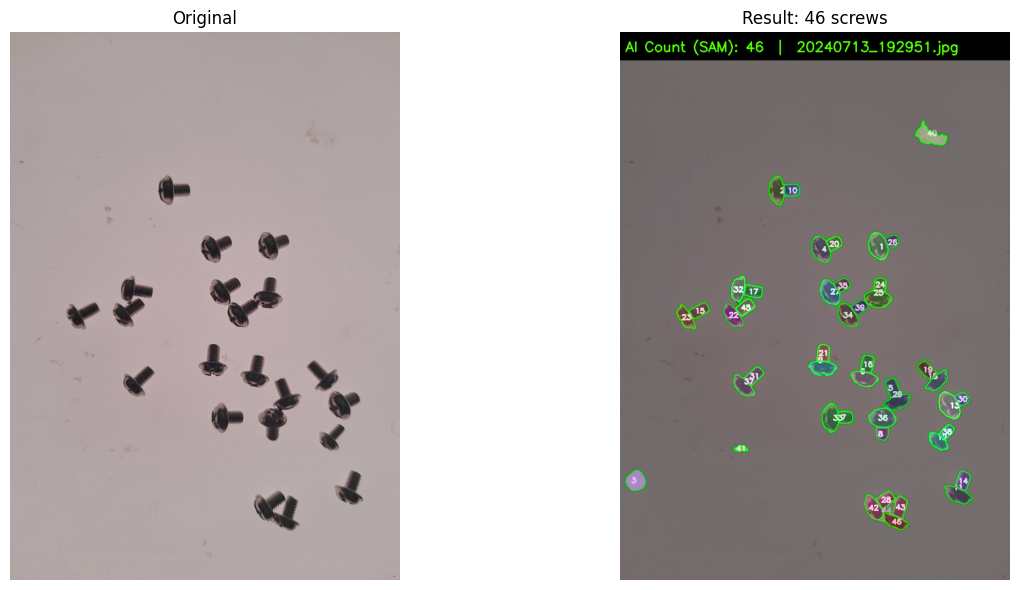

Detected: 46 items


In [62]:
result, count = count_screws_ai(image_paths[0], debug=True)
print(f'Detected: {count} items')

In [63]:
# Process all images
summary = []
for path in image_paths:
    fname = os.path.basename(path)
    print(f'Processing {fname}...')
    try:
        result, count = count_screws_ai(path)
        cv2.imwrite(os.path.join(OUTPUT_DIR, f'result_{fname}'), result)
        summary.append((fname, count, 'OK'))
        print(f'  => {count} items')
    except Exception as e:
        summary.append((fname, -1, str(e)))
        print(f'  => ERROR: {e}')

Processing 20240713_192951.jpg...
  Generating masks...
  Raw=68 → Filtered=65 → Final=46
  => 46 items
Processing 20240713_193135.jpg...
  Generating masks...
  Raw=57 → Filtered=54 → Final=42
  => 42 items
Processing 20240713_193650.jpg...
  Generating masks...
  Raw=12 → Filtered=11 → Final=11
  => 11 items
Processing 20240713_193659.jpg...
  Generating masks...
  Raw=15 → Filtered=13 → Final=13
  => 13 items
Processing 20240713_193831.jpg...
  Generating masks...
  Raw=103 → Filtered=101 → Final=100
  => 100 items
Processing 20240713_193839.jpg...
  Generating masks...
  Raw=90 → Filtered=88 → Final=85
  => 85 items
Processing 20240713_193907.jpg...
  Generating masks...
  Raw=69 → Filtered=67 → Final=66
  => 66 items
Processing 20240713_194200.jpg...
  Generating masks...
  Raw=58 → Filtered=50 → Final=48
  => 48 items
Processing 20240713_194206.jpg...
  Generating masks...
  Raw=38 → Filtered=28 → Final=26
  => 26 items
Processing 20240713_194215.jpg...
  Generating masks...
  Ra

In [64]:
summary = []
for path in image_paths:
    fname = os.path.basename(path)
    print(f'Processing: {fname}')
    try:
        result, count = count_screws_ai(path)
        out = os.path.join(OUTPUT_DIR, f'result_{fname}')
        cv2.imwrite(out, result)
        summary.append((fname, count, 'OK'))
        print(f'  => {count} items ✅')
    except Exception as e:
        summary.append((fname, -1, str(e)))
        print(f'  => ERROR: {e}')

Processing: 20240713_192951.jpg
  Generating masks...
  Raw=68 → Filtered=65 → Final=46
  => 46 items ✅
Processing: 20240713_193135.jpg
  Generating masks...
  Raw=57 → Filtered=54 → Final=42
  => 42 items ✅
Processing: 20240713_193650.jpg
  Generating masks...
  Raw=12 → Filtered=11 → Final=11
  => 11 items ✅
Processing: 20240713_193659.jpg
  Generating masks...
  Raw=15 → Filtered=13 → Final=13
  => 13 items ✅
Processing: 20240713_193831.jpg
  Generating masks...
  Raw=103 → Filtered=101 → Final=100
  => 100 items ✅
Processing: 20240713_193839.jpg
  Generating masks...
  Raw=90 → Filtered=88 → Final=85
  => 85 items ✅
Processing: 20240713_193907.jpg
  Generating masks...
  Raw=69 → Filtered=67 → Final=66
  => 66 items ✅
Processing: 20240713_194200.jpg
  Generating masks...
  Raw=58 → Filtered=50 → Final=48
  => 48 items ✅
Processing: 20240713_194206.jpg
  Generating masks...
  Raw=38 → Filtered=28 → Final=26
  => 26 items ✅
Processing: 20240713_194215.jpg
  Generating masks...
  Raw=

In [65]:
print('='*55)
print(f'{"Image":<35}{"Count":>8}  Status')
print('-'*55)
for f,c,s in summary: print(f'{f:<35}{c:>8}  {s}')
print('='*55)
ok = [(f,c) for f,c,s in summary if s=='OK']
print(f'Total: {len(summary)} | OK: {len(ok)} | Avg: {sum(c for _,c in ok)/max(len(ok),1):.1f}')

Image                                 Count  Status
-------------------------------------------------------
20240713_192951.jpg                      46  OK
20240713_193135.jpg                      42  OK
20240713_193650.jpg                      11  OK
20240713_193659.jpg                      13  OK
20240713_193831.jpg                     100  OK
20240713_193839.jpg                      85  OK
20240713_193907.jpg                      66  OK
20240713_194200.jpg                      48  OK
20240713_194206.jpg                      26  OK
20240713_194215.jpg                      48  OK
20240713_194232.jpg                      33  OK
20240713_194256.jpg                      20  OK
20240713_194316.jpg                      13  OK
20240713_194541.jpg                      76  OK
20240713_194551.jpg                      59  OK
20240713_194606.jpg                      98  OK
20240713_194621.jpg                     100  OK
20240713_194630.jpg                     132  OK
img1.jpg                    

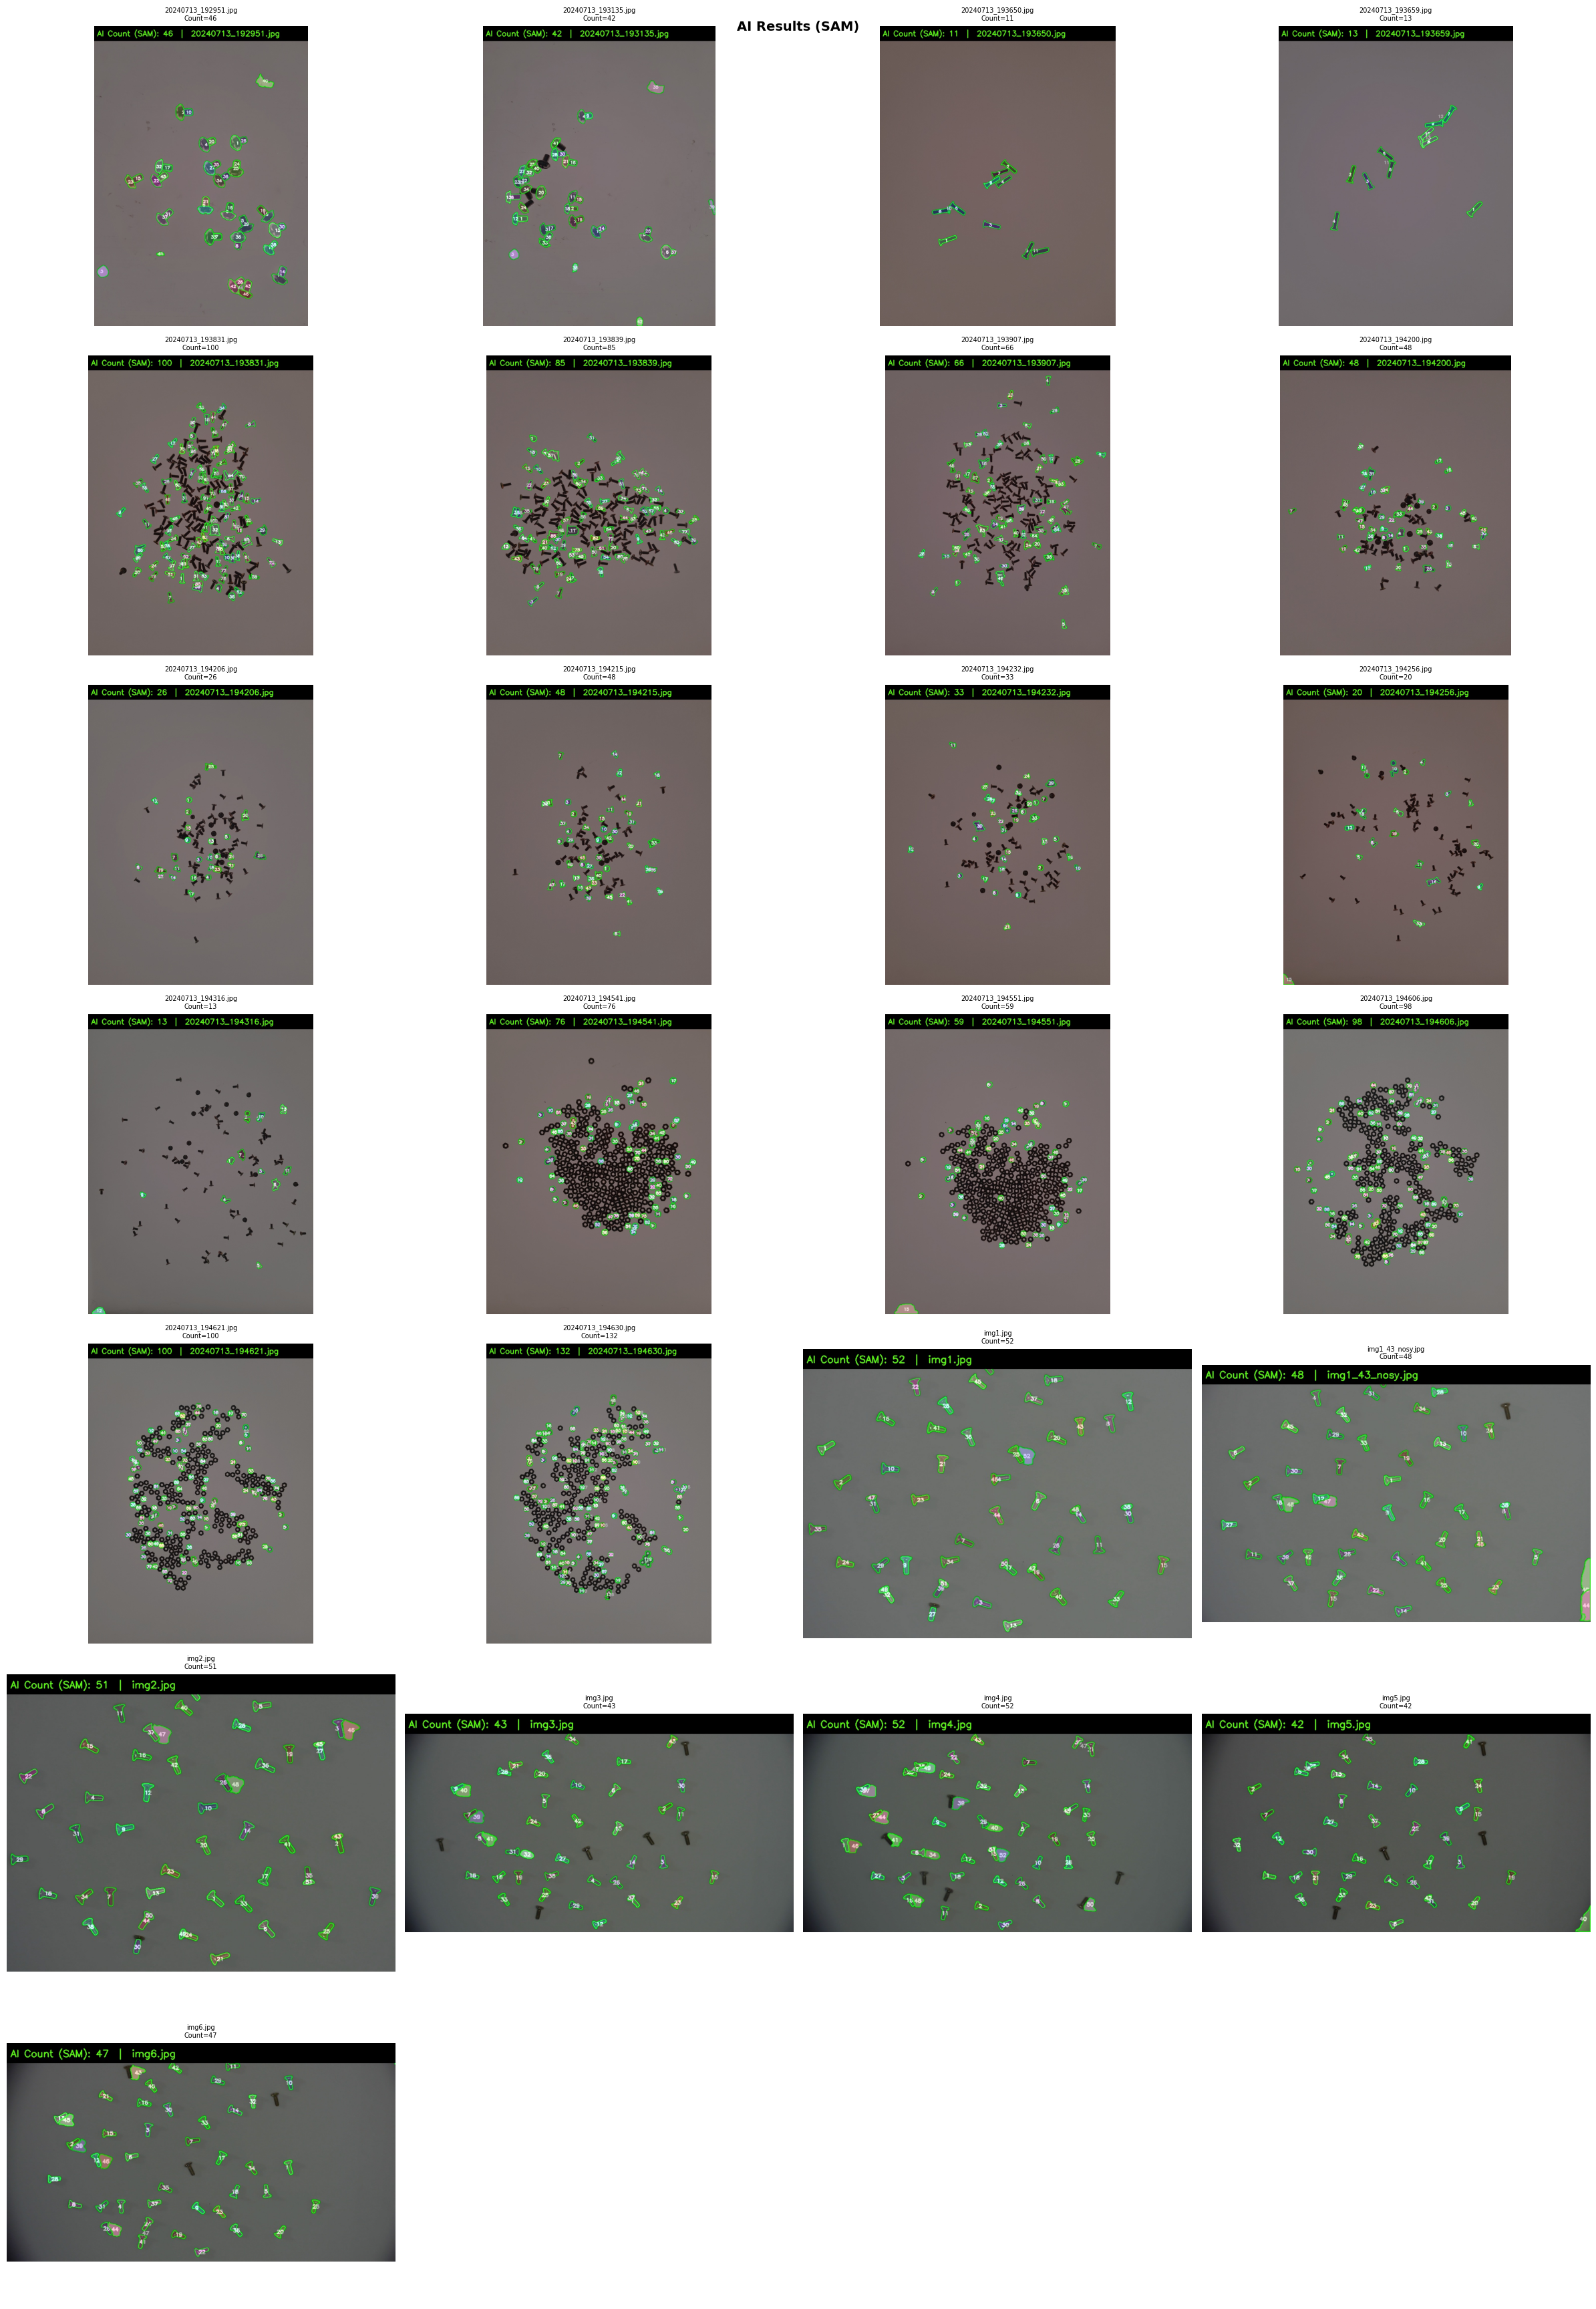

Grid saved!


In [66]:
n = len(image_paths)
cols = min(4, n)
rows = (n + cols - 1) // cols
fig, axes = plt.subplots(rows, cols, figsize=(6*cols, 5*rows))
axes = np.array(axes).flatten() if n > 1 else [axes]

for i, (path, (fname, count, _)) in enumerate(zip(image_paths, summary)):
    rp = os.path.join(OUTPUT_DIR, f'result_{fname}')
    if os.path.exists(rp):
        axes[i].imshow(cv2.cvtColor(cv2.imread(rp), cv2.COLOR_BGR2RGB))
    axes[i].set_title(f'{fname}\nCount={count}', fontsize=7)
    axes[i].axis('off')

for j in range(len(summary), len(axes)):
    axes[j].axis('off')

plt.suptitle('AI Results (SAM)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'ai_summary_grid.png'), dpi=120, bbox_inches='tight')
plt.show()
print('Grid saved!')

In [67]:
print('='*55)
print(f'{"Image":<35}{"Count":>8}  Status')
print('-'*55)
for f, c, s in summary:
    print(f'{f:<35}{c:>8}  {s}')
print('='*55)
ok = [(f,c) for f,c,s in summary if s=='OK']
print(f'Total: {len(summary)} | OK: {len(ok)} | Avg: {sum(c for _,c in ok)/max(len(ok),1):.1f}')

Image                                 Count  Status
-------------------------------------------------------
20240713_192951.jpg                      46  OK
20240713_193135.jpg                      42  OK
20240713_193650.jpg                      11  OK
20240713_193659.jpg                      13  OK
20240713_193831.jpg                     100  OK
20240713_193839.jpg                      85  OK
20240713_193907.jpg                      66  OK
20240713_194200.jpg                      48  OK
20240713_194206.jpg                      26  OK
20240713_194215.jpg                      48  OK
20240713_194232.jpg                      33  OK
20240713_194256.jpg                      20  OK
20240713_194316.jpg                      13  OK
20240713_194541.jpg                      76  OK
20240713_194551.jpg                      59  OK
20240713_194606.jpg                      98  OK
20240713_194621.jpg                     100  OK
20240713_194630.jpg                     132  OK
img1.jpg                    

## Training Method

**SAM ViT-B** — Pre-trained by Meta AI on the SA-1B dataset:
- 11 million images, 1 billion masks
- Zero-shot inference — no domain-specific training
- Checkpoint: `sam_vit_b_01ec64.pth` (375MB)

## If Annotated Data Were Available
Fine-tuning SAM's mask decoder:
```python
# Fine-tune with domain-specific prompts
from segment_anything import SamPredictor
predictor = SamPredictor(sam)
# Train mask decoder with annotated screw bounding boxes
```

## Parameter Tuning
| Parameter | Effect | Adjust if... |
|---|---|---|
| `PRED_IOU_THRESH` | Mask quality filter | Too many false positives |
| `POINTS_PER_SIDE` | Detection density | Missing screws in dense areas |
| `SCREW_MIN_FRAC` | Min object size | Small noise being counted |
| `SCREW_MAX_FRAC` | Max object size | Background being counted |